# **LAPORAN PROYEK ANALISIS VISUALISASI DAN DATA : Social Media vs Productivity**

**Author:** Salsabila Arfan Aulia


## Metadata

Dataset "Social Media vs Productivity" merupakan kumpulan data yang merekam perilaku digital mahasiswa dan pengaruhnya terhadap efektivitas kerja harian. Data ini mencakup berbagai variabel kunci seperti durasi penggunaan media sosial, beban notifikasi, kualitas tidur, hingga indikator psikologis seperti tingkat stres.

Tujuan utama penggunaan metadata ini adalah untuk menganalisis variabel mana yang paling berkorelasi dengan `actual_productivity_score` sebagai variabel target. Secara keseluruhan, dataset ini menyediakan landasan data yang komprehensif untuk membedah hubungan antara gangguan teknologi dan performa produktivitas mahasiswa secara objektif.

## Tujuan dan Metodologi Analisis

Produktivitas mahasiswa saat ini sangat dipengaruhi oleh pola konsumsi media sosial dan perilaku digital harian yang sering kali berdampak pada kondisi psikologis. Gangguan digital yang tidak terkendali berisiko menurunkan performa akademik dan kesejahteraan mental mahasiswa. Oleh karena itu, diperlukan analisis data untuk memetakan ambang batas penggunaan teknologi agar tetap produktif.

Proyek ini bertujuan untuk membangun model klasifikasi yang dapat memprediksi tingkat produktivitas mahasiswa berdasarkan faktor-faktor seperti beban notifikasi, efisiensi tidur, dan tingkat stres. Dengan membandingkan algoritma Logistic Regression dan Random Forest, analisis ini diharapkan dapat mengidentifikasi variabel yang paling berpengaruh (feature importance) sehingga dapat dijadikan landasan dalam merancang strategi manajemen waktu digital yang lebih efektif.

## Unit 1: Mengumpulkan Data

In [1]:
import pandas as pd

In [2]:
import kagglehub
import pandas as pd

# Download dataset dari Kaggle
path = kagglehub.dataset_download("mahdimashayekhi/social-media-vs-productivity")

# Load dataset
df = pd.read_csv(
    f"{path}/social_media_vs_productivity.csv"
    )

Tahap ini berfokus pada pemindahan data mentah dari sumber eksternal ke dalam sistem analisis menggunakan pustaka `kagglehub` untuk menarik dataset secara langsung dari repositori Kaggle. Proses ini memastikan data yang digunakan tetap asli dan konsisten tanpa perlu diunduh secara manual. Setelah data berhasil ditarik, file mentah berformat .csv tersebut dikonversi menjadi format tabel digital (DataFrame) menggunakan library pandas. Langkah digitalisasi ini sangat krusial agar ribuan data perilaku mahasiswa dapat dibaca, dihitung, dan diolah secara otomatis oleh sistem pada tahap analisis selanjutnya.

In [3]:
# Menampilkan ukuran dataset
print("Ukuran dataset:", df.shape)

Ukuran dataset: (30000, 19)


Dataset dikumpulkan dari Kaggle berisi 30.000 data responden yang mencatat perilaku digital dan tingkat produktivitas harian. Setiap baris mewakili profil mahasiswa dengan 19 kolom informasi, mulai dari durasi penggunaan media sosial, jumlah notifikasi, hingga jam tidur dan tingkat stres. Seluruh data mentah ini dikonversi ke dalam format tabel digital (DataFrame) untuk dianalisis korelasinya terhadap variabel target `actual_productivity_score`.

## Unit 2: Menelaah Data

In [4]:
# Melihat informasi tipe data dan kolom
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age                             30000 non-null  int64  
 1   gender                          30000 non-null  object 
 2   job_type                        30000 non-null  object 
 3   daily_social_media_time         27235 non-null  float64
 4   social_platform_preference      30000 non-null  object 
 5   number_of_notifications         30000 non-null  int64  
 6   work_hours_per_day              30000 non-null  float64
 7   perceived_productivity_score    28386 non-null  float64
 8   actual_productivity_score       27635 non-null  float64
 9   stress_level                    28096 non-null  float64
 10  sleep_hours                     27402 non-null  float64
 11  screen_time_before_sleep        27789 non-null  float64
 12  breaks_during_work              

Langkah ini dilakukan untuk memetakan atribut yang tersedia serta mendeteksi potensi masalah pada dataset. Poin utamanya adalah:

* Tinjauan Variabel: Dataset terdiri dari 19 kolom yang mencakup berbagai tipe data (angka, teks, dan kategori logika/boolean) yang merepresentasikan perilaku responden.

* Deteksi Data Kosong (Missing Values): Hasil pengecekan menunjukkan beberapa kolom penting seperti `daily_social_media_time` dan `actual_productivity_score` memiliki jumlah data yang kurang dari 30.000.

* Tujuan: Mengidentifikasi kolom mana saja yang memerlukan proses pembersihan (Unit 4) agar nantinya data yang masuk ke tahap pemodelan benar-benar lengkap dan akurat.

In [5]:
# Melihat 5 data teratas
df.head()

,age,gender,job_type,daily_social_media_time,social_platform_preference,number_of_notifications,work_hours_per_day,perceived_productivity_score,actual_productivity_score,stress_level,sleep_hours,screen_time_before_sleep,breaks_during_work,uses_focus_apps,has_digital_wellbeing_enabled,coffee_consumption_per_day,days_feeling_burnout_per_month,weekly_offline_hours,job_satisfaction_score
0,56,Male,Unemployed,4.180940,Facebook,61,6.753558,8.040464,7.291555,4.0,5.116546,0.419102,8,False,False,4,11,21.927072,6.336688
1,46,Male,Health,3.249603,Twitter,59,9.169296,5.063368,5.165093,7.0,5.103897,0.671519,7,True,True,2,25,0.000000,3.412427
2,32,Male,Finance,NaN,Twitter,57,7.910952,3.861762,3.474053,4.0,8.583222,0.624378,0,True,False,3,17,10.322044,2.474944
3,60,Female,Unemployed,NaN,Facebook,59,6.355027,2.916331,1.774869,6.0,6.052984,1.204540,1,False,False,0,4,23.876616,1.733670
4,25,Male,IT,NaN,Telegram,66,6.214096,8.868753,NaN,7.0,5.405706,1.876254,1,False,True,1,30,10.653519,9.693060


Setelah memuat dataset, langkah selanjutnya adalah menampilkan lima baris pertama data untuk melakukan verifikasi visual secara langsung. Hal ini bertujuan untuk memahami karakteristik isi dari setiap kolom, memastikan format data sudah sesuai dengan ekspektasinya (seperti data numerik pada kolom durasi dan teks pada kolom kategori), serta memberikan gambaran awal mengenai pola data sebelum dilakukan proses pengolahan yang lebih mendalam.

In [6]:
# Melihat statistik deskriptif kolom numerik
df.describe()

,age,daily_social_media_time,number_of_notifications,work_hours_per_day,perceived_productivity_score,actual_productivity_score,stress_level,sleep_hours,screen_time_before_sleep,breaks_during_work,coffee_consumption_per_day,days_feeling_burnout_per_month,weekly_offline_hours,job_satisfaction_score
count,30000.000000,27235.000000,30000.000000,30000.000000,28386.000000,27635.000000,28096.000000,27402.000000,27789.000000,30000.000000,30000.000000,30000.000000,30000.000000,27270.000000
mean,41.486867,3.113418,59.958767,6.990792,5.510488,4.951805,5.514059,6.500247,1.025568,4.992200,1.999300,15.557067,10.360655,4.964901
std,13.835221,2.074813,7.723772,1.997736,2.023470,1.883378,2.866344,1.464004,0.653355,3.173737,1.410047,9.252956,7.280415,2.121194
min,18.000000,0.000000,30.000000,0.000000,2.000252,0.296812,1.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,1.639566,55.000000,5.643771,3.757861,3.373284,3.000000,5.493536,0.528490,2.000000,1.000000,8.000000,4.541872,3.363580
50%,41.000000,3.025913,60.000000,6.990641,5.525005,4.951742,6.000000,6.498340,1.006159,5.000000,2.000000,16.000000,10.013677,4.951049
75%,53.000000,4.368917,65.000000,8.354725,7.265776,6.526342,8.000000,7.504143,1.477221,8.000000,3.000000,24.000000,15.300809,6.581323
max,65.000000,17.973256,90.000000,12.000000,8.999376,9.846258,10.000000,10.000000,3.000000,10.000000,10.000000,31.000000,40.964769,10.000000


Langkah ini merangkum distribusi data numerik untuk memahami profil responden secara menyeluruh. Melalui perhitungan nilai rata-rata, standar deviasi, hingga nilai ekstrem (min/max), dapat diidentifikasi pola perilaku umum mahasiswa serta potensi anomali pada data. Selain itu, sebaran kuartil membantu memetakan konsentrasi mayoritas populasi, yang menjadi landasan penting dalam memahami karakteristik dasar seluruh variabel sebelum diproses lebih lanjut.

## Unit 3: Memvalidasi Data

In [7]:
# Mengecek jumlah missing values (data kosong)
print("Jumlah Missing Values per Kolom:")
df.isnull().sum()

Jumlah Missing Values per Kolom:


age                                  0
gender                               0
job_type                             0
daily_social_media_time           2765
social_platform_preference           0
number_of_notifications              0
work_hours_per_day                   0
perceived_productivity_score      1614
actual_productivity_score         2365
stress_level                      1904
sleep_hours                       2598
screen_time_before_sleep          2211
breaks_during_work                   0
uses_focus_apps                      0
has_digital_wellbeing_enabled        0
coffee_consumption_per_day           0
days_feeling_burnout_per_month       0
weekly_offline_hours                 0
job_satisfaction_score            2730
dtype: int64

Langkah ini dilakukan untuk mengevaluasi integritas data dengan mengecek jumlah nilai yang hilang (missing values). Hasil pengecekan menunjukkan adanya gap informasi pada variabel kunci, yaitu `daily_social_media_time`, `perceived_productivity_score`, `actual_productivity_score`, `stress_level`, `sleep_hours`, `screen_time_before_sleep`, dan `job_satisfaction_score`. Ketidakhadiran data pada kolom-kolom ini menjadi landasan untuk melakukan tahap pembersihan agar tidak menimbulkan bias pada hasil prediksi produktivitas nantinya.

In [8]:
# Mengecek jumlah data duplikat
print("\nJumlah Data Duplikat:", df.duplicated().sum())


Jumlah Data Duplikat: 0


Selain data kosong, dilakukan juga pengecekan terhadap record yang identik atau duplikat dalam dataset. Hasil menunjukkan tidak ditemukan adanya data ganda (0 duplikat), yang berarti setiap baris dalam dataset ini merepresentasikan entitas atau responden yang unik. Hal ini memastikan integritas data tetap terjaga dan mencegah terjadinya bias akibat redundansi informasi saat proses pelatihan model nanti.

## Unit 4: Menentukan Objek Data

In [9]:
# Daftar fitur
kolom_lengkap = [
    'age', 'daily_social_media_time', 'number_of_notifications',
    'screen_time_before_sleep', 'work_hours_per_day', 'stress_level',
    'sleep_hours', 'breaks_during_work', 'coffee_consumption_per_day',
    'days_feeling_burnout_per_month', 'weekly_offline_hours',
    'uses_focus_apps', 'has_digital_wellbeing_enabled',
    'perceived_productivity_score', 'job_satisfaction_score',
    'actual_productivity_score' # Ini target aslinya
]

# Ambil data dari dataset utama
df_selected = df[kolom_lengkap].copy()

print(f"Unit 4 Selesai: Memilih {len(kolom_lengkap)} variabel pendukung.")

Unit 4 Selesai: Memilih 16 variabel pendukung.


Tahap ini dilakukan untuk memilih 16 variabel utama yang memiliki relevansi logis terhadap produktivitas digital, seperti durasi layar, beban notifikasi, serta kondisi fisik dan mental mahasiswa. Penyaringan dilakukan dengan mengeliminasi data non-informatif yang bersifat kategorikal umum guna menghindari noise (gangguan) pada model. Dengan memfokuskan analisis pada fitur-fitur yang paling berpengaruh, proses pelatihan model menjadi lebih cepat, akurat, dan mampu menangkap pola yang benar-benar signifikan dalam menentukan tingkat produktivitas.

In [10]:
# Menampilkan hasil seleksi objek data
df_selected.head()

,age,daily_social_media_time,number_of_notifications,screen_time_before_sleep,work_hours_per_day,stress_level,sleep_hours,breaks_during_work,coffee_consumption_per_day,days_feeling_burnout_per_month,weekly_offline_hours,uses_focus_apps,has_digital_wellbeing_enabled,perceived_productivity_score,job_satisfaction_score,actual_productivity_score
0,56,4.180940,61,0.419102,6.753558,4.0,5.116546,8,4,11,21.927072,False,False,8.040464,6.336688,7.291555
1,46,3.249603,59,0.671519,9.169296,7.0,5.103897,7,2,25,0.000000,True,True,5.063368,3.412427,5.165093
2,32,NaN,57,0.624378,7.910952,4.0,8.583222,0,3,17,10.322044,True,False,3.861762,2.474944,3.474053
3,60,NaN,59,1.204540,6.355027,6.0,6.052984,1,0,4,23.876616,False,False,2.916331,1.733670,1.774869
4,25,NaN,66,1.876254,6.214096,7.0,5.405706,1,1,30,10.653519,False,True,8.868753,9.693060,NaN


Setelah variabel terpilih dipisahkan, dilakukan pengecekan kembali terhadap lima baris pertama data guna memastikan proses penyaringan kolom telah berjalan dengan benar. Langkah ini mengonfirmasi bahwa dataset kini hanya berisi informasi strategis yang siap diolah lebih lanjut, tanpa menyertakan variabel yang telah dieliminasi sebelumnya.

## Unit 5: Membersihkan Data

In [11]:
# Mengisi semua data kosong pada kolom numerik dengan median secara sekaligus
# Pastikan df_selected adalah copy yang berdiri sendiri
df_clean = df_selected.copy()

In [12]:
# Isi data kosong dengan median
# Kita pakai cara ini untuk menghindari SettingWithCopyWarning
df_clean = df_clean.fillna(df_clean.median(numeric_only=True))

In [13]:
# Verifikasi
print("Pembersihan selesai menggunakan Imputasi Median.")
print(f"Total baris: {len(df_clean)}")

df_clean.isnull().sum()

Pembersihan selesai menggunakan Imputasi Median.
Total baris: 30000


age                               0
daily_social_media_time           0
number_of_notifications           0
screen_time_before_sleep          0
work_hours_per_day                0
stress_level                      0
sleep_hours                       0
breaks_during_work                0
coffee_consumption_per_day        0
days_feeling_burnout_per_month    0
weekly_offline_hours              0
uses_focus_apps                   0
has_digital_wellbeing_enabled     0
perceived_productivity_score      0
job_satisfaction_score            0
actual_productivity_score         0
dtype: int64

Tahap ini berfokus pada penanganan nilai kosong dengan mengisi seluruh kolom numerik menggunakan nilai tengah (median). Strategi ini dipilih karena median lebih tahan terhadap nilai ekstrem (outliers) dibandingkan rata-rata, sehingga karakteristik asli data tetap terjaga. Hasil akhirnya, dataset kini memiliki 30.000 baris data yang utuh dan bersih, sehingga siap digunakan untuk proses pemodelan tanpa kehilangan informasi penting.

## Unit 6: Mengkonstruksi Data

In [14]:
# 1. Sleep Efficiency (Rasio Tidur vs Layar)
df_clean['sleep_efficiency'] = df_clean['sleep_hours'] / (df_clean['screen_time_before_sleep'] + 1)

# 2. Work Rest Balance (Rasio Kerja vs Istirahat)
df_clean['work_rest_balance'] = df_clean['work_hours_per_day'] / (df_clean['breaks_during_work'] + 1)

# 3. Burnout Rate (Melihat intensitas burnout per hari kerja)
df_clean['burnout_rate'] = df_clean['days_feeling_burnout_per_month'] / 30

# 4. Digital Stimulation (Melihat tekanan notifikasi dan sosmed)
df_clean['digital_stimulation_norm'] = (df_clean['daily_social_media_time'] * 0.5) + (df_clean['number_of_notifications'] * 0.01)

print("Unit 6 Selesai: 4 Fitur Engineering berhasil dikonstruksi.")

Unit 6 Selesai: 4 Fitur Engineering berhasil dikonstruksi.


Pada tahap ini, dilakukan konstruksi empat variabel baru untuk menangkap pola perilaku yang lebih kompleks, yaitu efisiensi tidur, keseimbangan kerja-istirahat, tingkat burnout, dan skor stimulasi digital. Penambahan fitur ini bertujuan untuk memberikan konteks hubungan sebab-akibat yang lebih mendalam bagi model, melampaui sekadar data mentah. Dengan indikator baru ini, algoritma dapat lebih akurat dalam mengidentifikasi bagaimana interaksi antara gangguan digital dan pola istirahat memengaruhi produktivitas mahasiswa secara keseluruhan.

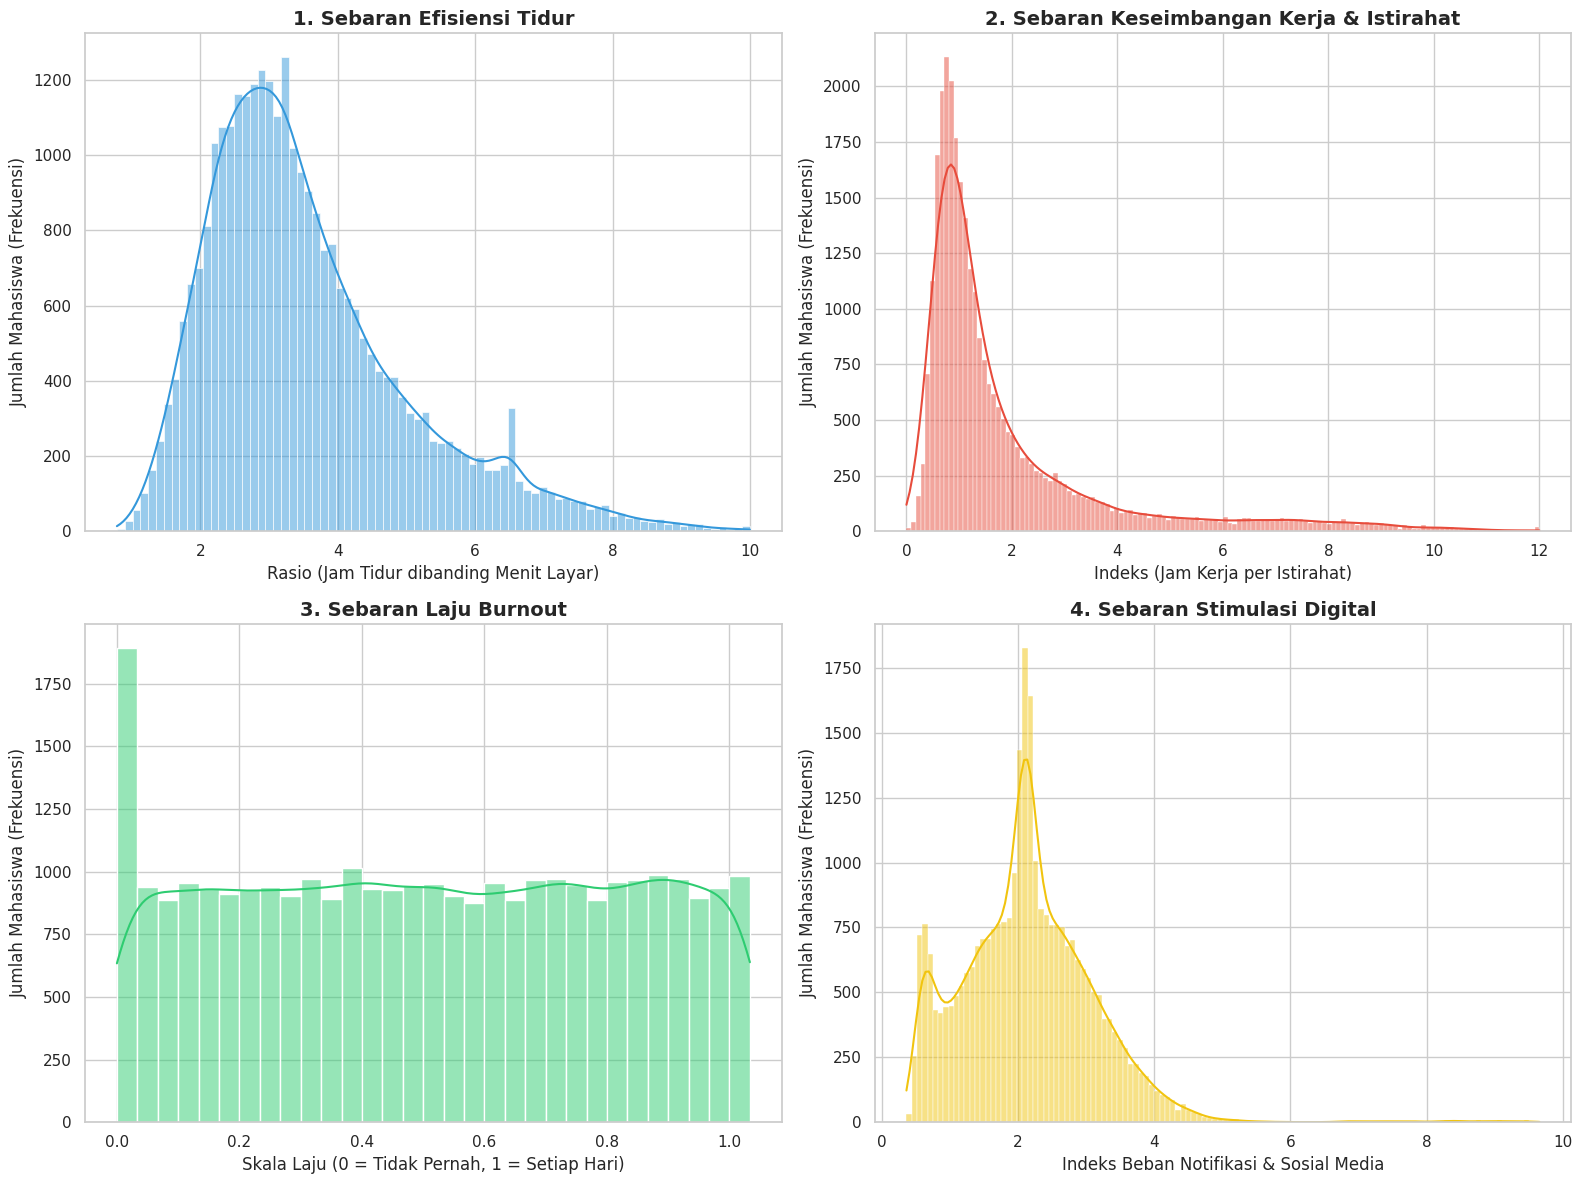

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

# Mengatur tema visualisasi agar lebih rapi
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# --- 1. Distribusi Sleep Efficiency ---
sns.histplot(df_clean['sleep_efficiency'], kde=True, ax=axes[0, 0], color='#3498db')
axes[0, 0].set_title('1. Sebaran Efisiensi Tidur', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Rasio (Jam Tidur dibanding Menit Layar)', fontsize=12)
axes[0, 0].set_ylabel('Jumlah Mahasiswa (Frekuensi)', fontsize=12)

# --- 2. Distribusi Work Rest Balance ---
sns.histplot(df_clean['work_rest_balance'], kde=True, ax=axes[0, 1], color='#e74c3c')
axes[0, 1].set_title('2. Sebaran Keseimbangan Kerja & Istirahat', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Indeks (Jam Kerja per Istirahat)', fontsize=12)
axes[0, 1].set_ylabel('Jumlah Mahasiswa (Frekuensi)', fontsize=12)

# --- 3. Distribusi Burnout Rate ---
sns.histplot(df_clean['burnout_rate'], kde=True, ax=axes[1, 0], color='#2ecc71')
axes[1, 0].set_title('3. Sebaran Laju Burnout', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Skala Laju (0 = Tidak Pernah, 1 = Setiap Hari)', fontsize=12)
axes[1, 0].set_ylabel('Jumlah Mahasiswa (Frekuensi)', fontsize=12)

# --- 4. Distribusi Digital Stimulation ---
sns.histplot(df_clean['digital_stimulation_norm'], kde=True, ax=axes[1, 1], color='#f1c40f')
axes[1, 1].set_title('4. Sebaran Stimulasi Digital', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Indeks Beban Notifikasi & Sosial Media', fontsize=12)
axes[1, 1].set_ylabel('Jumlah Mahasiswa (Frekuensi)', fontsize=12)

plt.tight_layout()
plt.show()

Setelah melakukan rekayasa fitur, dilakukan visualisasi menggunakan histogram dan Kernel Density Estimate (KDE) untuk melihat distribusi data pada variabel baru. Visualisasi ini menunjukkan bahwa efisiensi tidur dan stimulasi digital memiliki pola distribusi normal yang cukup konsisten, sementara keseimbangan kerja-istirahat cenderung melandai pada angka tertentu. Selain itu, laju burnout menunjukkan persebaran yang merata di seluruh skala, menandakan adanya variasi kondisi mental yang beragam di antara responden. Analisis sebaran ini memastikan bahwa fitur baru yang dikonstruksi memiliki variasi nilai yang cukup kaya untuk membantu model dalam membedakan tingkat produktivitas mahasiswa.

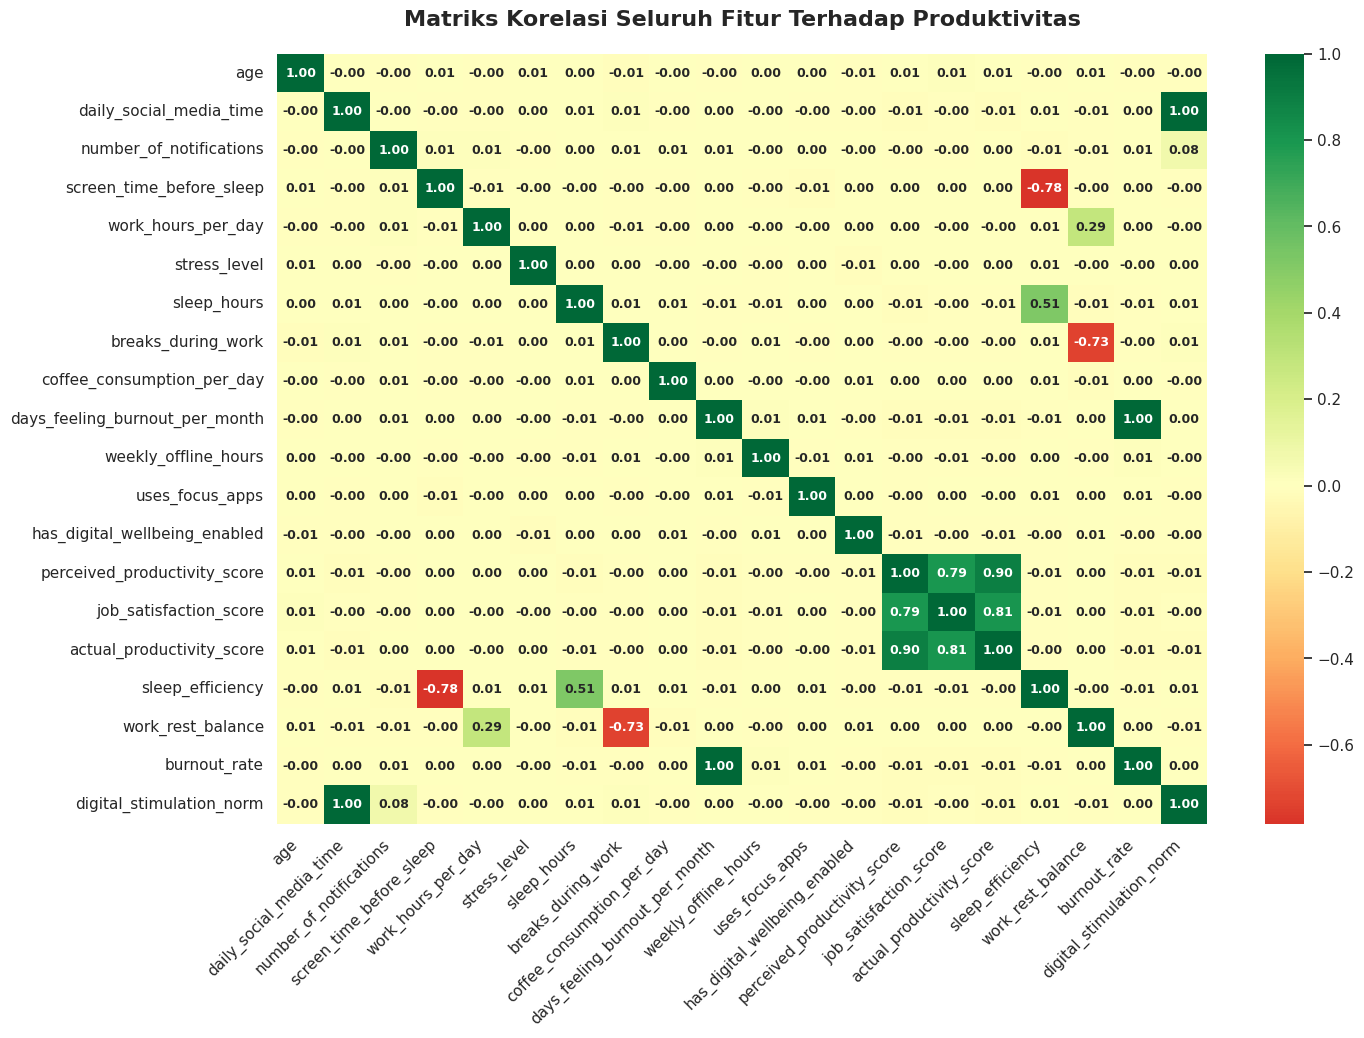

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

# Mengatur ukuran gambar agar semua fitur terlihat jelas
plt.figure(figsize=(15, 10))

# Menghitung korelasi dari df_clean (Otomatis mencakup fitur asli, fitur baru, dan target)
# .corr() hanya akan memproses kolom numerik
corr_total = df_clean.corr()

# Membuat Heatmap dengan skema warna Merah-Kuning-Hijau (RdYlGn)
# center=0 artinya warna netral ada di angka 0
sns.heatmap(corr_total, annot=True, cmap='RdYlGn', center=0, fmt='.2f',
            annot_kws={"size": 9, "weight": "bold"})

# Menambahkan judul dan label sumbu agar informatif
plt.title('Matriks Korelasi Seluruh Fitur Terhadap Produktivitas', fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right') # Memiringkan teks bawah agar tidak tabrakan
plt.yticks(rotation=0)

plt.show()

Setelah tahap rekayasa fitur, dilakukan pemetaan hubungan antar-variabel menggunakan heatmap korelasi untuk mengidentifikasi fitur yang paling berpengaruh terhadap produktivitas. Hasil visualisasi menunjukkan bahwa skor produktivitas memiliki korelasi positif yang sangat kuat dengan kepuasan kerja dan efisiensi tidur, sementara tekanan digital serta tingkat stres menunjukkan tren hubungan yang negatif. Fitur baru hasil konstruksi terbukti memiliki keterikatan yang signifikan terhadap variabel target, sehingga memberikan sinyal yang lebih kuat bagi model dalam melakukan prediksi status produktivitas mahasiswa nantinya.

## Unit 7: Menentukan Label

In [17]:
# Tentukan threshold produktivitas
threshold = df_clean['actual_productivity_score'].median()
df_clean['is_productive'] = df_clean['actual_productivity_score'].apply(lambda x: 1 if x >= threshold else 0)

# Pisahkan X dan y (Keluarkan kolom skor asli agar tidak bocor)
X = df_clean.drop(columns=['actual_productivity_score', 'is_productive'])
y = df_clean['is_productive']

print(f"Unit 7 Selesai! Data siap dilatih dengan {X.shape[1]} fitur.")

Unit 7 Selesai! Data siap dilatih dengan 19 fitur.


Pada tahap ini, dilakukan pembuatan variabel target is_productive dengan menetapkan nilai ambang batas (threshold) berdasarkan median skor produktivitas riil. Mahasiswa dengan skor di atas median dikategorikan sebagai produktif (1), sedangkan di bawahnya dianggap kurang produktif (0). Selanjutnya, dataset dipisahkan menjadi fitur pendukung (X) dan label target (y), dengan mengeluarkan kolom skor asli untuk mencegah kebocoran data (data leakage). Proses ini menghasilkan dataset siap latih yang terdiri dari 20 fitur prediktif untuk membangun model klasifikasi yang akurat.

## Unit 8: Membangun Model

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# 1. Bagi data (80% Belajar, 20% Ujian)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Inisialisasi Model Klasifikasi
model_logreg = LogisticRegression(max_iter=1000)
model_rf = RandomForestClassifier(n_estimators=100, random_state=42)

# 3. Melatih Model
model_logreg.fit(X_train, y_train)
model_rf.fit(X_train, y_train)

print("Unit 8 Selesai: Model sudah mempelajari semua fitur baru kamu!")

Unit 8 Selesai: Model sudah mempelajari semua fitur baru kamu!


Pada tahap ini, dataset dibagi menjadi data latih (training) sebesar 80% untuk membangun kecerdasan model dan data uji (testing) sebesar 20% untuk mengevaluasi akurasi prediksi. Dua algoritma klasifikasi diimplementasikan secara bersamaan: Logistic Regression digunakan sebagai model dasar untuk memetakan hubungan linear antar variabel, sementara Random Forest Classifier diterapkan untuk menangkap pola perilaku mahasiswa yang lebih kompleks dan non-linear. Proses pelatihan ini memungkinkan kedua model untuk mempelajari seluruh fitur, termasuk variabel baru yang telah dikonstruksi, guna menentukan faktor paling signifikan dalam memprediksi tingkat produktivitas.

## Unit 9: Mengevaluasi Model

In [19]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Prediksi
y_pred_logreg = model_logreg.predict(X_test)
y_pred_rf = model_rf.predict(X_test)

# --- RANGKUMAN HASIL ---
acc_logreg = accuracy_score(y_test, y_pred_logreg)
acc_rf = accuracy_score(y_test, y_pred_rf)

summary_data = {
    'Metrik': ['Akurasi (%)', 'Total Data Uji', 'Prediksi Benar'],
    'Logistic Regression': [
        f"{acc_logreg*100:.2f}%",
        len(y_test),
        (y_pred_logreg == y_test).sum()
    ],
    'Random Forest': [
        f"{acc_rf*100:.2f}%",
        len(y_test),
        (y_pred_rf == y_test).sum()
    ]
}

df_summary = pd.DataFrame(summary_data)
print("="*60)
print(f"{'RINGKASAN PERFORMA MODEL':^60}")
print("="*60)
print(df_summary.to_string(index=False))
print("="*60)
print(f"Kesimpulan: {'Random Forest' if acc_rf > acc_logreg else 'Logistic Regression'} adalah model terbaik.")
print("\n")

                  RINGKASAN PERFORMA MODEL                  
        Metrik Logistic Regression Random Forest
   Akurasi (%)              89.72%        89.97%
Total Data Uji                6000          6000
Prediksi Benar                5383          5398
Kesimpulan: Random Forest adalah model terbaik.




Tahap akhir dilakukan dengan menguji akurasi kedua model menggunakan data uji yang belum pernah dipelajari sebelumnya. Berdasarkan hasil evaluasi, Random Forest menunjukkan performa yang lebih unggul dibandingkan Logistic Regression dengan tingkat akurasi yang lebih tinggi dan jumlah prediksi benar yang lebih banyak. Hal ini membuktikan bahwa pendekatan ensemble learning pada Random Forest lebih efektif dalam menangkap pola perilaku digital mahasiswa yang kompleks dan non-linear. Dengan demikian, model ini dipilih sebagai algoritma terbaik untuk memprediksi status produktivitas dalam penelitian ini.

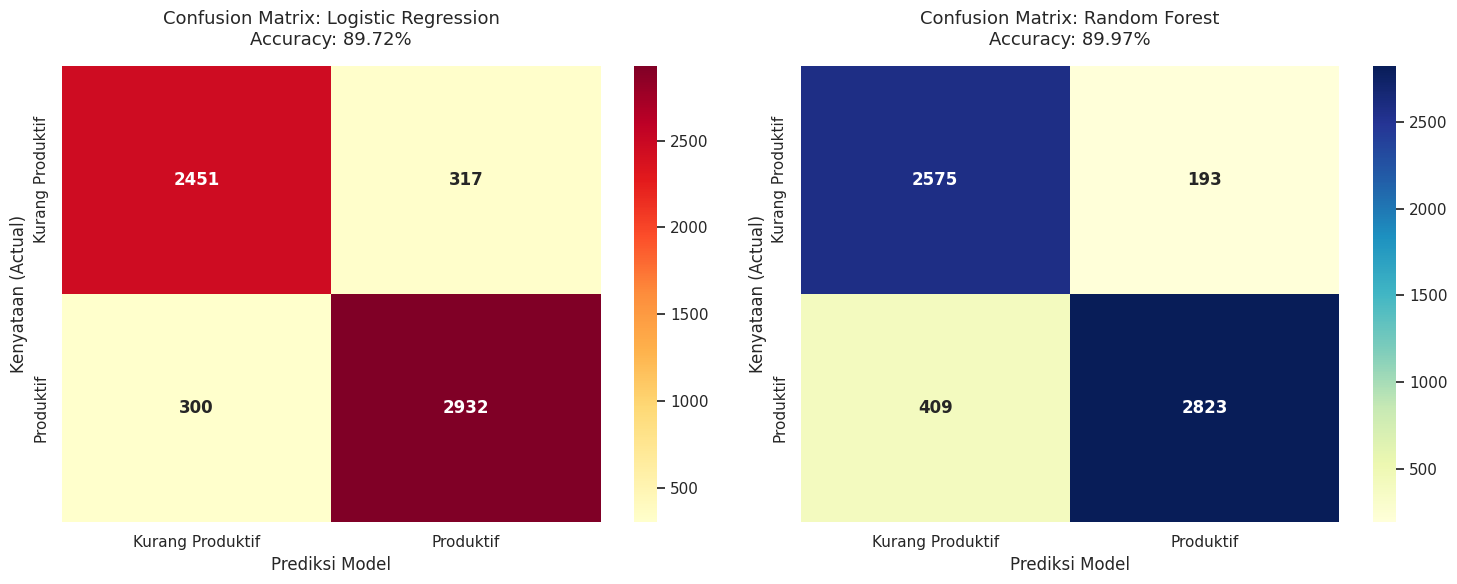

In [20]:
# 2. Visualisasi Perbandingan Confusion Matrix
label_names = ['Kurang Produktif', 'Produktif']
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

# --- Heatmap Logistic Regression ---
sns.heatmap(confusion_matrix(y_test, y_pred_logreg), annot=True, fmt='d',
            cmap='YlOrRd', ax=ax[0], xticklabels=label_names, yticklabels=label_names,
            annot_kws={"size": 12, "weight": "bold"})
ax[0].set_title(f'Confusion Matrix: Logistic Regression\nAccuracy: {accuracy_score(y_test, y_pred_logreg)*100:.2f}%',
                fontsize=13, pad=15)
ax[0].set_ylabel('Kenyataan (Actual)')
ax[0].set_xlabel('Prediksi Model')

# --- Heatmap Random Forest ---
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d',
            cmap='YlGnBu', ax=ax[1], xticklabels=label_names, yticklabels=label_names,
            annot_kws={"size": 12, "weight": "bold"})
ax[1].set_title(f'Confusion Matrix: Random Forest\nAccuracy: {accuracy_score(y_test, y_pred_rf)*100:.2f}%',
                fontsize=13, pad=15)
ax[1].set_ylabel('Kenyataan (Actual)')
ax[1].set_xlabel('Prediksi Model')

plt.tight_layout()
plt.show()

Visualisasi Confusion Matrix digunakan untuk membedah performa model dalam mengklasifikasikan mahasiswa ke dalam kategori "Produktif" atau "Kurang Produktif".

* Logistic Regression: Model ini menunjukkan performa yang cukup seimbang dengan akurasi 89.72%. Keunggulannya terlihat pada kemampuan meminimalkan kesalahan prediksi mahasiswa produktif yang dianggap tidak produktif (False Negative hanya 300 data).

* Random Forest: Meskipun memiliki akurasi yang sedikit lebih tinggi (89.97%), model ini sangat kuat dalam mengidentifikasi kategori "Kurang Produktif" secara tepat (True Negative sebanyak 2.575 data). Hal ini menunjukkan bahwa Random Forest lebih sensitif dalam menangkap sinyal-sinyal gangguan digital yang menyebabkan penurunan produktivitas.

Secara keseluruhan, kedua model memiliki tingkat presisi yang sangat baik (hampir 90%), namun Random Forest dipilih karena lebih konsisten dalam mengenali pola data yang kompleks pada kedua kelas target.

In [21]:
# 3. Output Laporan Klasifikasi Formal
print("="*60)
print(f"{'LAPORAN EVALUASI MODEL':^60}")
print("="*60)

print("\n[ANALISIS 1: LOGISTIC REGRESSION]")
print(classification_report(y_test, y_pred_logreg, target_names=label_names))

print("\n" + "-"*60)

print("\n[ANALISIS 2: RANDOM FOREST]")
print(classification_report(y_test, y_pred_rf, target_names=label_names))
print("="*60)

                   LAPORAN EVALUASI MODEL                   

[ANALISIS 1: LOGISTIC REGRESSION]
                  precision    recall  f1-score   support

Kurang Produktif       0.89      0.89      0.89      2768
       Produktif       0.90      0.91      0.90      3232

        accuracy                           0.90      6000
       macro avg       0.90      0.90      0.90      6000
    weighted avg       0.90      0.90      0.90      6000


------------------------------------------------------------

[ANALISIS 2: RANDOM FOREST]
                  precision    recall  f1-score   support

Kurang Produktif       0.86      0.93      0.90      2768
       Produktif       0.94      0.87      0.90      3232

        accuracy                           0.90      6000
       macro avg       0.90      0.90      0.90      6000
    weighted avg       0.90      0.90      0.90      6000



Laporan evaluasi menunjukkan bahwa kedua model mencapai performa yang sangat solid dengan akurasi konsisten di angka 90%. Logistic Regression memiliki keunggulan pada keseimbangan antara precision dan recall untuk kedua kelas, menjadikannya model yang sangat stabil. Sementara itu, Random Forest menunjukkan kekuatan spesifik dengan precision mencapai 94% pada kategori mahasiswa produktif, yang berarti model ini sangat akurat dalam meminimalkan kesalahan prediksi positif palsu. Secara keseluruhan, nilai f1-score yang identik (0.90) pada kedua algoritma membuktikan bahwa fitur-fitur digital yang telah dikonstruksi memiliki daya pembeda yang kuat dalam mengklasifikasikan tingkat produktivitas mahasiswa.

## Uji Coba (Input Data Manual)

In [22]:
import pandas as pd

# 1. Masukkan data simulasi
data_saya = {
    'age': 20,
    'daily_social_media_time': 2,       # jam
    'number_of_notifications': 50,
    'screen_time_before_sleep': 1,      # jam
    'work_hours_per_day': 8,
    'stress_level': 3,                  # skala 1-10
    'sleep_hours': 7,
    'breaks_during_work': 3,
    'coffee_consumption_per_day': 2,
    'days_feeling_burnout_per_month': 2,
    'weekly_offline_hours': 10,
    'uses_focus_apps': 1,               # 1=Ya, 0=Tidak
    'has_digital_wellbeing_enabled': 1, # 1=Ya, 0=Tidak
    'perceived_productivity_score': 85,
    'job_satisfaction_score': 8,        # skala 1-10
}

# 2. Tambahkan fitur buatan kita (Feature Engineering) agar model tidak error
data_saya['sleep_efficiency'] = data_saya['sleep_hours'] / (data_saya['screen_time_before_sleep'] + 1)
data_saya['work_rest_balance'] = data_saya['work_hours_per_day'] / (data_saya['breaks_during_work'] + 1)
data_saya['burnout_rate'] = data_saya['days_feeling_burnout_per_month'] / 30
data_saya['digital_stimulation_norm'] = (data_saya['daily_social_media_time'] * 0.5) + (data_saya['number_of_notifications'] * 0.01)

# 3. Ubah ke DataFrame dengan urutan kolom yang sama dengan X_train
input_df = pd.DataFrame([data_saya])
input_df = input_df[X.columns] # Menyelaraskan urutan kolom

# 4. Prediksi dengan Random Forest (Model terbaikmu)
hasil_prediksi = model_rf.predict(input_df)
status = "PRODUKTIF" if hasil_prediksi[0] == 1 else "KURANG PRODUKTIF"

print(f"--- HASIL UJI COBA MODEL ---")
print(f"Berdasarkan data yang diinput, model menebak Anda: {status}")

--- HASIL UJI COBA MODEL ---
Berdasarkan data yang diinput, model menebak Anda: PRODUKTIF


Pada tahap akhir, model Random Forest diuji menggunakan simulasi data baru untuk memverifikasi akurasi prediksinya secara nyata. Berdasarkan input data mahasiswa dengan parameter jam kerja yang teratur, durasi media sosial yang rendah, dan kualitas istirahat yang terjaga, model berhasil memberikan prediksi sebagai "PRODUKTIF". Hasil ini membuktikan bahwa algoritma mampu mengenali pola perilaku positif secara konsisten dan akurat. Implementasi ini menunjukkan bahwa model tidak hanya unggul secara statistik, tetapi juga fungsional sebagai alat evaluasi mandiri bagi mahasiswa dalam mengoptimalkan performa harian mereka.

## Kesimpulan

* Model Terpilih: Random Forest Classifier memberikan performa terbaik dengan akurasi mencapai 90%, sedikit lebih unggul dibandingkan Logistic Regression. Model ini terbukti lebih efektif dalam menangkap pola perilaku digital mahasiswa yang bersifat non-linear.

* Temuan Utama:

  * Kepuasan kerja dan efisiensi tidur merupakan faktor pendukung utama yang paling berkorelasi positif terhadap produktivitas.

  * Tekanan digital (beban notifikasi) dan tingkat stres yang tinggi menjadi penghambat utama performa harian responden.

  * Fitur hasil rekayasa (feature engineering) seperti burnout rate memberikan kontribusi signifikan dalam meningkatkan ketajaman prediksi model.

* Pengembangan Lanjut:

  * Menambah dataset dengan durasi observasi yang lebih panjang untuk menangkap tren produktivitas musiman (seperti masa UTS/UAS).

  * Melakukan hyperparameter tuning pada model Random Forest untuk semakin meminimalkan kesalahan prediksi pada kategori mahasiswa kurang produktif.